# Parte 3 — Treinamento e comparação dos modelos

## Objetivo

Comparar os classificadores da **Saikit-learn do grupo** no dataset MAGIC
Gamma Telescope, selecionar uma configuração pela validação e registrar
os resultados de forma reproduzível.

Esta etapa contempla:

1. Escolha e configuração dos modelos.
2. Treinamento com a biblioteca do grupo.
3. Comparação por métricas e gráficos.
4. Registro das métricas, previsões e configurações.

O código usa nomes e comentários em inglês. As explicações e os rótulos
apresentados ao leitor estão em português.

O notebook **reutiliza `preprocessamento.ipynb`**: divisão aleatória
70%/15%/15%, semente 42 e padronização ajustada no treino. Todos os modelos
usam os mesmos conjuntos. O teste fica reservado para a avaliação final.

Salve este arquivo em `analysis/classificacao/notebooks/` do
[repositório de aplicação](https://github.com/feliperibeiro-impatech/saikit-learn-aplicacao).


## 1. Bibliotecas

Utilizamos os classificadores e as métricas da biblioteca do grupo.
NumPy auxilia na organização dos dados; pandas registra as tabelas;
matplotlib produz os gráficos.

Se necessário, instale as dependências no kernel com:

```python
%pip install saikit-learn numpy pandas matplotlib nbformat
```

A biblioteca instalada precisa incluir a correção do voto do KNN
verificada na seção 3.


In [1]:
import os
import sys
import json
import hashlib
from pathlib import Path
from datetime import datetime, timezone
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import saikit_learn
from IPython.display import display, Markdown

from saikit_learn.linear_model import LogisticRegression
from saikit_learn.neighbors import KNN
from saikit_learn.discriminant_analysis import LDA, QDA
from saikit_learn.classification_metrics import ClassificationMetrics

print(f'Versão da Saikit-learn: {saikit_learn.__version__}')


Versão da Saikit-learn: 0.2.1


## 2. Reutilização do pré-processamento

Executamos o notebook existente no mesmo kernel com `%run`. Ele já produz
`X_train_scaled`, `X_val_scaled`, `X_test_scaled` e os respectivos rótulos.
O treinamento consome esses resultados.

O bloco abaixo localiza o repositório e executa o pré-processamento a
partir da pasta esperada pelos caminhos relativos do projeto. A pasta de
trabalho original é restaurada ao final.

Os rótulos são codificados como `h = 0` e `g = 1`. Criamos vetores NumPy
para atender à interface dos classificadores, preservando a ordem das linhas.


In [2]:
project_root = next(
    (directory for directory in [Path.cwd(), *Path.cwd().parents]
     if (directory / 'analysis/classificacao/notebooks/preprocessamento.ipynb').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Execute este notebook dentro do repositório saikit-learn-aplicacao.')

preprocessing_path = project_root / 'analysis/classificacao/notebooks/preprocessamento.ipynb'
original_directory = Path.cwd()
try:
    os.chdir(preprocessing_path.parent)
    get_ipython().run_line_magic('run', preprocessing_path.name)
finally:
    os.chdir(original_directory)

# Use the outputs of the existing preprocessing notebook.
train_features = np.asarray(X_train_scaled, dtype=float)
valid_features = np.asarray(X_val_scaled, dtype=float)
test_features = np.asarray(X_test_scaled, dtype=float)
train_labels = np.asarray(y_train, dtype=int)
valid_labels = np.asarray(y_val, dtype=int)
test_labels = np.asarray(y_test, dtype=int)
validation_row_ids = np.asarray(val_indices, dtype=int)

for features, labels in [(train_features, train_labels), (valid_features, valid_labels)]:
    if features.ndim != 2 or labels.ndim != 1 or len(features) != len(labels):
        raise ValueError('Os atributos e rótulos possuem dimensões incompatíveis.')
    if not np.isfinite(features).all() or not np.array_equal(np.unique(labels), [0, 1]):
        raise ValueError('Verifique valores não finitos e a presença das duas classes.')

split_summary = pd.DataFrame({
    'Conjunto': ['Treinamento', 'Validação', 'Teste reservado'],
    'Observações': [len(train_labels), len(valid_labels), len(test_labels)],
    'Características': [train_features.shape[1], valid_features.shape[1], test_features.shape[1]],
})
display(split_summary)


Média do treinamento:
[-4.08265880e-17  6.19069831e-17 -6.07062011e-17 -7.17800796e-17
  2.68708328e-16 -1.49430649e-17  2.40156400e-18  1.70777885e-17
 -3.20208533e-18 -2.84451914e-16]

Desvio padrão do treinamento:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Treinamento: (13314, 10) (13314,)
Validação: (2853, 10) (2853,)
Teste: (2853, 10) (2853,)
Treinamento:
class
1    64.969205
0    35.030795
Name: proportion, dtype: float64

Validação:
class
1    63.792499
0    36.207501
Name: proportion, dtype: float64

Teste:
class
1    65.264634
0    34.735366
Name: proportion, dtype: float64
Treinamento
NaN: 0
Infinitos: 0

Validação
NaN: 0
Infinitos: 0

Teste
NaN: 0
Infinitos: 0



,Conjunto,Observações,Características
0,Treinamento,13314,10
1,Validação,2853,10
2,Teste reservado,2853,10


## 3. Verificação do KNN

Na revisão consultada da biblioteca, o voto do KNN pode selecionar uma
classe fora do conjunto de candidatas com maior contagem. Por exemplo,
os vizinhos `[1, 1, 0]` devem produzir a previsão `1`.

Se a célula abaixo detectar o problema, corrija a linha de seleção em
`saikit_learn/neighbors/knn.py` para:

```python
predicted_labels.append(label[candidates][np.argmin(first_pos[candidates])])
```

Depois, reinicie o kernel. Esta verificação interrompe a comparação se a
versão instalada ainda apresentar o erro; ela não altera o pacote instalado.


In [3]:
probe_model = KNN(k=3)
probe_model.fit(np.array([[0.0], [0.1], [0.2]]), np.array([1, 1, 0]))
if probe_model.predict(np.array([[0.05]]))[0] != 1:
    raise RuntimeError('Corrija o voto do KNN conforme a seção anterior e reinicie o kernel.')
print('Verificação do voto do KNN: aprovada.')


Verificação do voto do KNN: aprovada.


## 4. Escolha e configuração dos modelos

Comparamos quatro configurações iniciais:

| Modelo | Característica |
|---|---|
| Regressão logística | Fronteira de decisão linear |
| KNN | Classificação por proximidade, com cinco vizinhos |
| LDA | Uma matriz de covariância comum às classes |
| QDA | Uma matriz de covariância para cada classe |

Os parâmetros ficam centralizados no código abaixo. As configurações
constituem um ponto de partida; esta etapa não executa busca exaustiva de
hiperparâmetros. A seleção será feita entre essas configurações.

Também calculamos uma referência simples: prever para todas as observações
a classe mais frequente **no treino**. Essa referência ajuda a interpretar
os ganhos dos classificadores e não participa da seleção final.


In [4]:
model_specs = {
    'logistic_regression': {
        'name': 'Regressão logística',
        'constructor': LogisticRegression,
        'parameters': {'learning_rate': 0.5, 'max_iter': 10000, 'tol': 1e-6, 'alpha': 0.0},
    },
    'knn': {
        'name': 'KNN (k=5)',
        'constructor': KNN,
        'parameters': {'k': 5, 'p': 2},
    },
    'lda': {'name': 'LDA', 'constructor': LDA, 'parameters': {}},
    'qda': {'name': 'QDA', 'constructor': QDA, 'parameters': {'reg_param': 0.0}},
}
models = {
    model_id: specification['constructor'](**specification['parameters'])
    for model_id, specification in model_specs.items()
}

display(pd.DataFrame([
    {'Modelo': specification['name'], 'Parâmetros': specification['parameters']}
    for specification in model_specs.values()
]))


,Modelo,Parâmetros
0,Regressão logística,"{'learning_rate': 0.5, 'max_iter': 10000, 'tol..."
1,KNN (k=5),"{'k': 5, 'p': 2}"
2,LDA,{}
3,QDA,{'reg_param': 0.0}


## 5. Métricas e critério de comparação

As métricas são calculadas por `ClassificationMetrics`, da Saikit-learn.

- **Acurácia:** proporção de previsões corretas.
- **Precisão de gama:** entre as previsões de gama, quantas estão corretas.
- **Recall de gama:** proporção dos eventos gama identificados.
- **F1 de gama:** média harmônica entre precisão e recall dessa classe.
- **F1 macro:** média do F1 das duas classes, com o mesmo peso para cada classe.
- **Acurácia balanceada:** média do recall das duas classes.
- **Taxa de falsos positivos:** fração de hádrons classificados como gama.

Usaremos o **maior F1 macro na validação** como critério inicial. Em caso
de empate, preferimos a menor taxa de falsos positivos. Um último desempate
usa o identificador do modelo, garantindo uma ordenação determinística.

Esse critério evita depender somente da acurácia. A interpretação também
deve considerar o custo dos erros: no MAGIC, confundir hádrons com gama é
particularmente relevante. A matriz de confusão usa linhas para classes
reais e colunas para classes previstas, na ordem `[h, g]`.


In [5]:
def compute_metrics(true_labels, predicted_labels):
    """Compute classification metrics with the group's library."""
    evaluator = ClassificationMetrics(true_labels, predicted_labels, labels=[0, 1])
    confusion = evaluator.confusion_matrix()
    true_negatives, false_positives, false_negatives, true_positives = confusion.ravel()
    metrics = {
        'accuracy': float(evaluator.score('accuracy')),
        'precision_gamma': float(evaluator.score('precision', pos_label=1)),
        'recall_gamma': float(evaluator.score('recall', pos_label=1)),
        'f1_gamma': float(evaluator.score('f1', pos_label=1)),
        'f1_macro': float(evaluator.score('f1', average='macro')),
        'balanced_accuracy': float(evaluator.score('recall', average='macro')),
        'false_positive_rate': float(false_positives / max(false_positives + true_negatives, 1)),
    }
    return metrics, confusion


majority_class = int(np.bincount(train_labels).argmax())
baseline_predictions = np.full(valid_labels.shape, majority_class, dtype=int)
baseline_metrics, baseline_confusion = compute_metrics(valid_labels, baseline_predictions)
print(f'Classe mais frequente no treino: {"gama" if majority_class == 1 else "hádron"}.')


Classe mais frequente no treino: gama.


## 6. Treinamento e avaliação na validação

Todos os modelos são ajustados no treino e avaliados na mesma validação.
Registramos os tempos de treino e previsão separadamente: o KNN realiza
boa parte de seu trabalho ao prever novas observações.

Também verificamos a convergência da regressão logística. Caso ela não
convirja, sua configuração precisa ser revista antes da comparação final.
Os tempos registrados descrevem esta execução e variam conforme o computador.


In [6]:
result_rows = []
validation_predictions = {}
confusion_matrices = {}
training_diagnostics = {}

for model_id, model in models.items():
    start_time = perf_counter()
    model.fit(train_features, train_labels)
    training_seconds = perf_counter() - start_time

    start_time = perf_counter()
    predictions = np.asarray(model.predict(valid_features), dtype=int).reshape(-1)
    prediction_seconds = perf_counter() - start_time

    if predictions.shape != valid_labels.shape:
        raise ValueError('O modelo retornou um número incorreto de previsões.')
    metrics, confusion = compute_metrics(valid_labels, predictions)
    validation_predictions[model_id] = predictions
    confusion_matrices[model_id] = confusion
    result_rows.append({
        'model_id': model_id,
        'model_name': model_specs[model_id]['name'],
        **metrics,
        'training_seconds': training_seconds,
        'prediction_seconds': prediction_seconds,
    })

    if hasattr(model, 'converged_'):
        training_diagnostics[model_id] = {
            'converged': bool(np.all(model.converged_)),
            'iterations': model.n_iter_.tolist(),
        }
    print(f"{model_specs[model_id]['name']}: treinamento e validação concluídos.")

results_table = pd.DataFrame(result_rows).sort_values(
    ['f1_macro', 'false_positive_rate', 'model_id'],
    ascending=[False, True, True],
).reset_index(drop=True)

metric_titles = {
    'model_name': 'Modelo',
    'accuracy': 'Acurácia',
    'precision_gamma': 'Precisão de gama',
    'recall_gamma': 'Recall de gama',
    'f1_gamma': 'F1 de gama',
    'f1_macro': 'F1 macro',
    'balanced_accuracy': 'Acurácia balanceada',
    'false_positive_rate': 'Taxa de falsos positivos',
    'training_seconds': 'Treino (s)',
    'prediction_seconds': 'Previsão (s)',
}
display(results_table[list(metric_titles)].rename(columns=metric_titles).round(4))
display(pd.DataFrame([{'Modelo': 'Referência: classe majoritária', **baseline_metrics}])
        .rename(columns=metric_titles).round(4))

logistic_converged = training_diagnostics['logistic_regression']['converged']
print('Convergência da regressão logística:', 'sim' if logistic_converged else 'não')


Regressão logística: treinamento e validação concluídos.
KNN (k=5): treinamento e validação concluídos.
LDA: treinamento e validação concluídos.
QDA: treinamento e validação concluídos.
Convergência da regressão logística: sim


,Modelo,Acurácia,Precisão de gama,Recall de gama,F1 de gama,F1 macro,Acurácia balanceada,Taxa de falsos positivos,Treino (s),Previsão (s)
0,KNN (k=5),0.8258,0.8213,0.9291,0.8719,0.7999,0.7864,0.3562,0.0000,2.3197
1,Regressão logística,0.7753,0.7905,0.8813,0.8335,0.7441,0.7349,0.4114,0.8280,0.0001
2,QDA,0.7869,0.7740,0.9407,0.8492,0.7430,0.7283,0.4840,0.0009,0.0006
3,LDA,0.7669,0.7764,0.8912,0.8299,0.7299,0.7196,0.4521,0.0012,0.0236


,Modelo,Acurácia,Precisão de gama,Recall de gama,F1 de gama,F1 macro,Acurácia balanceada,Taxa de falsos positivos
0,Referência: classe majoritária,0.6379,0.6379,1.0,0.7789,0.3895,0.5,1.0


## 7. Comparação visual dos resultados

O primeiro gráfico compara F1 macro; o segundo destaca a taxa de falsos
positivos. Valores maiores são desejáveis no primeiro e menores no segundo.
A linha tracejada apresenta a referência da classe majoritária.


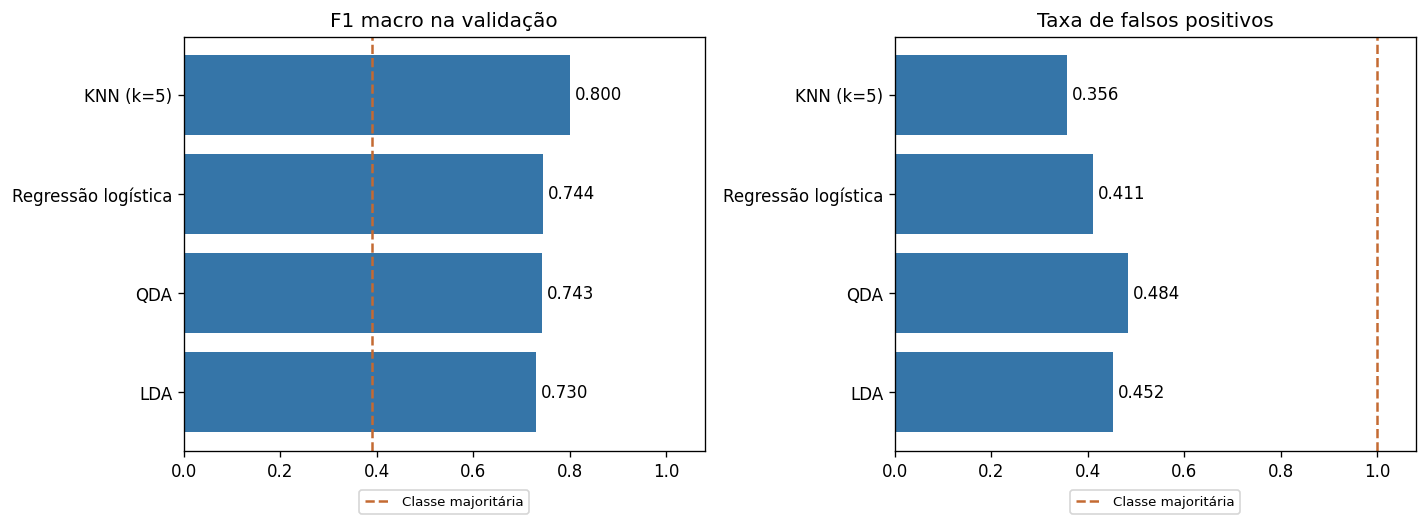

In [7]:
figure, axes = plt.subplots(1, 2, figsize=(12, 4.5))
positions = np.arange(len(results_table))
model_names = results_table['model_name'].tolist()

for axis, metric, title, baseline_value in [
    (axes[0], 'f1_macro', 'F1 macro na validação', baseline_metrics['f1_macro']),
    (axes[1], 'false_positive_rate', 'Taxa de falsos positivos', baseline_metrics['false_positive_rate']),
]:
    values = results_table[metric].to_numpy()
    axis.barh(positions, values, color='#3575A8')
    axis.set_yticks(positions, model_names)
    axis.invert_yaxis()
    axis.set_xlim(0, 1.08)
    axis.set_title(title)
    axis.axvline(baseline_value, color='#C46A32', linestyle='--', label='Classe majoritária')
    for position, value in zip(positions, values):
        axis.text(value + 0.01, position, f'{value:.3f}', va='center')
    axis.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), fontsize=8)

figure.tight_layout()
plt.show()


## 8. Matrizes de confusão

Os valores na diagonal correspondem às previsões corretas. O elemento da
primeira linha e segunda coluna conta os **hádrons classificados como gama**.
O elemento da segunda linha e primeira coluna conta os eventos gama
classificados como hádrons.


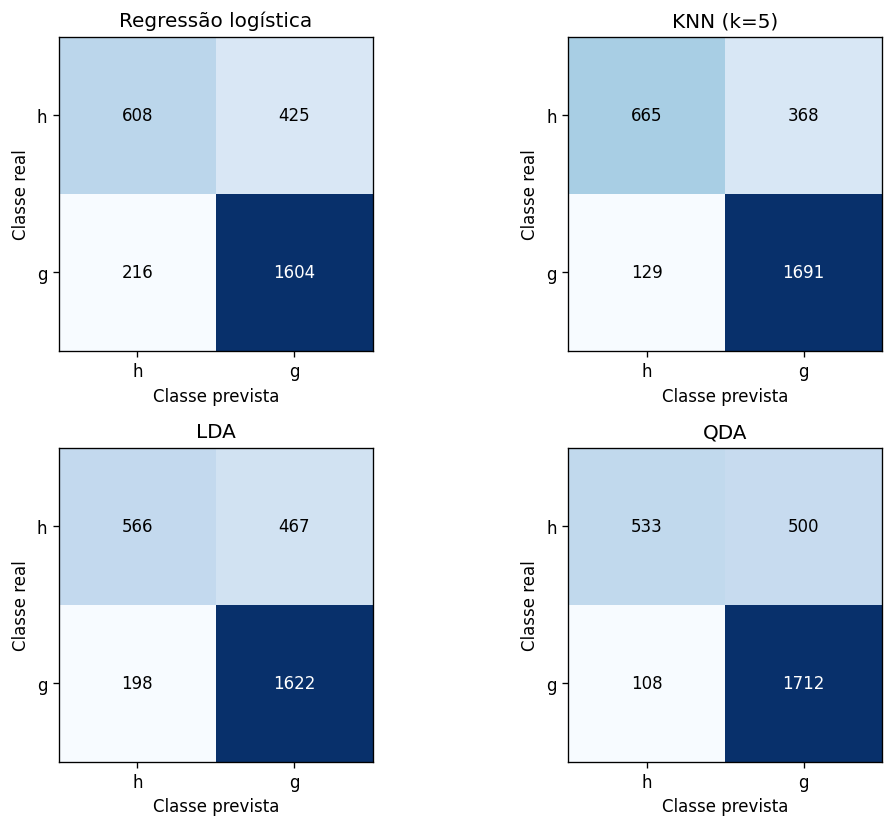

In [8]:
figure, axes = plt.subplots(2, 2, figsize=(9, 7))
for axis, (model_id, confusion) in zip(axes.ravel(), confusion_matrices.items()):
    axis.imshow(confusion, cmap='Blues')
    for row in range(2):
        for column in range(2):
            text_color = 'white' if confusion[row, column] > confusion.max() / 2 else 'black'
            axis.text(column, row, f'{confusion[row, column]:.0f}',
                      ha='center', va='center', color=text_color)
    axis.set_xticks([0, 1], ['h', 'g'])
    axis.set_yticks([0, 1], ['h', 'g'])
    axis.set(xlabel='Classe prevista', ylabel='Classe real', title=model_specs[model_id]['name'])
figure.tight_layout()
plt.show()


## 9. Diagnóstico adicional: ROC da regressão logística

A regressão logística da biblioteca disponibiliza `predict_proba`.
Usamos essas probabilidades para construir sua curva ROC e calcular a AUC
com NumPy. Scores empatados são agrupados antes do cálculo.

Na revisão consultada, KNN, LDA e QDA ainda não expõem probabilidades ou
scores em sua interface pública. Assim, esta curva descreve apenas a
logística; a seleção comum aos quatro modelos continua baseada no F1 macro.
Não usamos rótulos discretos para substituir os scores na AUC.

A documentação do [MAGIC na UCI](https://archive.ics.uci.edu/dataset/159/magic+gamma+telescope)
destaca a análise ROC, especialmente na região de baixa taxa de falsos
positivos. Uma comparação ROC entre todos os classificadores requer
acrescentar essa saída aos demais modelos.


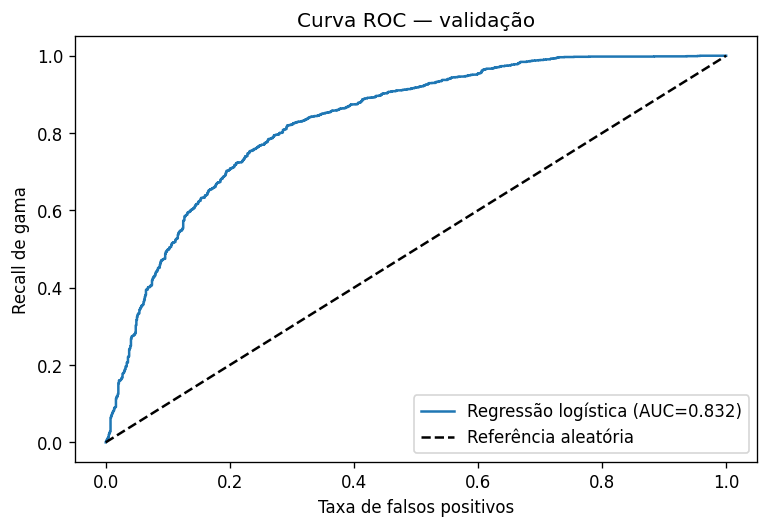

In [9]:
def compute_roc_curve(true_labels, scores):
    """Build a binary ROC curve, grouping observations with equal scores."""
    order = np.argsort(-scores, kind='stable')
    sorted_scores = scores[order]
    positives = true_labels[order] == 1
    threshold_indices = np.r_[np.flatnonzero(np.diff(sorted_scores)), len(scores) - 1]
    true_positive_rates = np.r_[0, np.cumsum(positives)[threshold_indices] / positives.sum()]
    false_positive_rates = np.r_[0, np.cumsum(~positives)[threshold_indices] / (~positives).sum()]
    thresholds = np.r_[np.inf, sorted_scores[threshold_indices]]
    area = np.sum(np.diff(false_positive_rates) *
                  (true_positive_rates[1:] + true_positive_rates[:-1]) / 2)
    return false_positive_rates, true_positive_rates, thresholds, float(area)


logistic_model = models['logistic_regression']
positive_column = int(np.flatnonzero(logistic_model.classes_ == 1)[0])
logistic_scores = logistic_model.predict_proba(valid_features)[:, positive_column]
false_positive_rates, true_positive_rates, thresholds, logistic_auc = compute_roc_curve(
    valid_labels, logistic_scores
)
roc_table = pd.DataFrame({
    'false_positive_rate': false_positive_rates,
    'true_positive_rate': true_positive_rates,
    'threshold': thresholds,
})

figure, axis = plt.subplots(figsize=(6.5, 4.5))
axis.plot(false_positive_rates, true_positive_rates, label=f'Regressão logística (AUC={logistic_auc:.3f})')
axis.plot([0, 1], [0, 1], 'k--', label='Referência aleatória')
axis.set(xlabel='Taxa de falsos positivos', ylabel='Recall de gama', title='Curva ROC — validação')
axis.legend()
figure.tight_layout()
plt.show()


## 10. Seleção pela validação e interpretação

A configuração selecionada é a de maior F1 macro entre as quatro avaliadas,
com os desempates definidos anteriormente. O relatório por classe ajuda a
identificar diferenças de desempenho entre hádrons e eventos gama.

Essa decisão é uma seleção pela validação. A estimativa de desempenho final
depende da avaliação posterior no conjunto de teste reservado.


In [10]:
selected_row = results_table.iloc[0]
selected_model_id = str(selected_row['model_id'])
selected_model = models[selected_model_id]
selected_predictions = validation_predictions[selected_model_id]
selected_evaluator = ClassificationMetrics(valid_labels, selected_predictions, labels=[0, 1])

class_report = pd.DataFrame([
    {
        'Classe': class_name,
        'Precisão': selected_evaluator.score('precision', pos_label=class_index),
        'Recall': selected_evaluator.score('recall', pos_label=class_index),
        'F1': selected_evaluator.score('f1', pos_label=class_index),
        'Observações': int(np.sum(valid_labels == class_index)),
    }
    for class_index, class_name in [(0, 'Hádron (h)'), (1, 'Gama (g)')]
])

display(Markdown(
    f"**Configuração selecionada:** {model_specs[selected_model_id]['name']}. "
    f"Na validação, obteve F1 macro de **{selected_row['f1_macro']:.4f}**, "
    f"acurácia de **{selected_row['accuracy']:.2%}** e taxa de falsos positivos "
    f"de **{selected_row['false_positive_rate']:.2%}**."
))
display(class_report.round(4))


**Configuração selecionada:** KNN (k=5). Na validação, obteve F1 macro de **0.7999**, acurácia de **82.58%** e taxa de falsos positivos de **35.62%**.

,Classe,Precisão,Recall,F1,Observações
0,Hádron (h),0.8375,0.6438,0.7280,1033
1,Gama (g),0.8213,0.9291,0.8719,1820


## 11. Registro dos resultados

Os arquivos ficam em `analysis/classificacao/results/part3/`:

| Arquivo | Conteúdo |
|---|---|
| `validation_metrics.csv` | Métricas e tempos dos quatro classificadores |
| `baseline_metrics.csv` | Métricas da classe majoritária |
| `validation_predictions.csv` | Índices originais, classes reais e previsões |
| `confusion_*.csv` | Matrizes de confusão |
| `logistic_roc.csv` | Pontos e limiares da ROC da logística |
| `class_report.csv` | Relatório por classe da configuração selecionada |
| `experiment_config.json` | Parâmetros, versões, divisão e decisão de seleção |

Os nomes das colunas dos arquivos são mantidos em inglês. A configuração
registra também o hash do pré-processamento e dos dados para identificar
exatamente as entradas utilizadas nesta execução.


In [11]:
output_directory = project_root / 'analysis/classificacao/results/part3'
output_directory.mkdir(parents=True, exist_ok=True)

results_table.to_csv(output_directory / 'validation_metrics.csv', index=False)
pd.DataFrame([baseline_metrics]).to_csv(output_directory / 'baseline_metrics.csv', index=False)

prediction_table = pd.DataFrame({'row_index': validation_row_ids, 'true_label': valid_labels})
for model_id, predictions in validation_predictions.items():
    prediction_table[model_id] = predictions
prediction_table.to_csv(output_directory / 'validation_predictions.csv', index=False)

for model_id, confusion in confusion_matrices.items():
    pd.DataFrame(confusion, index=['true_h', 'true_g'], columns=['predicted_h', 'predicted_g']).to_csv(
        output_directory / f'confusion_{model_id}.csv'
    )
roc_table.to_csv(output_directory / 'logistic_roc.csv', index=False)
class_report.rename(columns={
    'Classe': 'class_name', 'Precisão': 'precision', 'Recall': 'recall',
    'F1': 'f1', 'Observações': 'support',
}).to_csv(output_directory / 'class_report.csv', index=False)

experiment_config = {
    'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'dataset': 'MAGIC Gamma Telescope',
    'label_mapping': {'h': 0, 'g': 1},
    'split': {
        'random_seed': 42,
        'fractions': {'train': 0.70, 'validation': 0.15, 'test': 0.15},
        'counts': {'train': len(train_labels), 'validation': len(valid_labels), 'test': len(test_labels)},
        'preprocessing_sha256': hashlib.sha256(preprocessing_path.read_bytes()).hexdigest(),
        'data_sha256': hashlib.sha256((project_root / 'data/raw/magic04.data').read_bytes()).hexdigest(),
    },
    'models': {
        model_id: {'class_name': specification['constructor'].__name__, 'parameters': specification['parameters']}
        for model_id, specification in model_specs.items()
    },
    'training_diagnostics': training_diagnostics,
    'knn_voting_check_passed': True,
    'baseline_class': majority_class,
    'selection': {
        'primary_metric': 'f1_macro',
        'tie_breaker': 'false_positive_rate',
        'selected_model_id': selected_model_id,
        'selected_parameters': model_specs[selected_model_id]['parameters'],
        'validation_metrics': {metric: float(selected_row[metric]) for metric in baseline_metrics},
    },
    'logistic_validation_auc': logistic_auc,
    'test_evaluated': False,
    'versions': {
        'saikit_learn': saikit_learn.__version__,
        'numpy': np.__version__,
        'pandas': pd.__version__,
        'python': sys.version.split()[0],
    },
}
(output_directory / 'experiment_config.json').write_text(
    json.dumps(experiment_config, ensure_ascii=False, indent=2), encoding='utf-8'
)
print('Resultados registrados em analysis/classificacao/results/part3/.')


Resultados registrados em analysis/classificacao/results/part3/.


## Conclusão da parte 3

Os quatro classificadores foram comparados com os mesmos dados de treino
e validação. O critério de seleção foi explicitado, as métricas foram
registradas e as previsões ficaram disponíveis para inspeção.

Na próxima etapa, após fixar as escolhas, avalie a configuração selecionada
no teste reservado. Caso decida reajustar em treino + validação, use um
modelo novo e ajuste novamente a padronização nesse conjunto ampliado.

As conclusões desta etapa se referem às configurações avaliadas e à divisão
utilizada. A análise dos falsos positivos e a futura comparação ROC dos
quatro métodos devem orientar a discussão física do problema.
